## 1. Import

In [1]:
import sys
import json
import time
import copy
import gc
import hashlib
import shutil
import tempfile
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm

LIBRARY_VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "h5py": h5py.__version__,
    "joblib": joblib.__version__,
    "matplotlib": version("matplotlib"),
    "tqdm": version("tqdm"),
}

print(pd.Series(LIBRARY_VERSIONS, name="version").to_string())
print("Imports completed. This notebook runs on CPU.")


python          3.13.18
numpy             2.1.3
pandas            2.3.3
scikit-learn      1.6.1
h5py             3.14.0
joblib            1.6.0
matplotlib       3.10.0
tqdm             4.67.3
Imports completed. This notebook runs on CPU.


## 2. Config

In [2]:
INPUT_DIR = Path("/kaggle/input/notebooks/trngtnbi/datapreprocessing/real_vs_sdxl_pixels_plus_features_224")
HOG_PATH = INPUT_DIR / "pixels_hog_features.h5"
LBP_PATH = INPUT_DIR / "pixels_lbp_features.h5"
HSV12_PATH = INPUT_DIR / "pixels_hsv12_features.h5"
ALL_PATH = INPUT_DIR / "pixels_all_features.h5"

OUTPUT_DIR = Path("/kaggle/working/real_vs_sdxl_svm_benchmark")
MODEL_DIR = OUTPUT_DIR / "models"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
for directory in [OUTPUT_DIR, MODEL_DIR, PREDICTION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 128
CPU_THREADS = 4
MAX_EPOCHS = 20
PATIENCE = 5
MIN_DELTA = 1e-4
STRICT_COUNTS = True

SPLITS = ["train", "val", "test"]
CLASSES = np.array([0, 1], dtype=np.uint8)
CLASS_NAMES = ["Real", "SDXL"]
METRIC_COLUMNS = ["accuracy", "precision", "recall", "f1"]
EXPECTED_COUNTS = {"train": [7000, 7000], "val": [1500, 1500], "test": [1500, 1500]}

PIXEL_DIM = 224 * 224 * 3
HOG_DIM = 6084
LBP_DIM = 10
HSV12_DIM = 1728
ALL_FEATURE_DIM = HOG_DIM + LBP_DIM + HSV12_DIM

# Hinge loss trains a linear SVM with SGD
# The training loop handles shuffling, epochs, and validation-based stopping.
SVM_CONFIG = {
    "loss": "hinge",
    "penalty": "l2",
    "alpha": 1e-4,
    "learning_rate": "optimal",
    "average": True,
    "fit_intercept": True,
    "shuffle": False,
    "random_state": SEED,
    "max_iter": 1,
    "tol": None,
    "early_stopping": False,
    "class_weight": None,
}

# Reference: Bottou (2012), Stochastic Gradient Descent Tricks, Sections 4-5.
# Alpha, batch size, epoch limit, and patience are fixed benchmark choices.
METHOD_REFERENCE = {
    "author": "Leon Bottou",
    "year": 2012,
    "title": "Stochastic Gradient Descent Tricks",
    "url": "https://leon.bottou.org/publications/pdf/tricks-2012.pdf",
    "used_for": "SGD training of L2-regularized linear SVM; shuffling and validation monitoring",
}

RUN_CONFIG = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "cpu_threads": CPU_THREADS,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "svm": SVM_CONFIG,
    "method_reference": METHOD_REFERENCE,
    "parameter_source": "Fixed benchmark settings; not a reproduction of all paper parameters",
    "scaler": "StandardScaler fitted on train only",
    "pca": None,
    "positive_label": 1,
    "selection_metric": "validation_accuracy",
    "decision_threshold": 0.0,
    "input_files": {"hog": str(HOG_PATH), "lbp": str(LBP_PATH),
                    "hsv12": str(HSV12_PATH), "all": str(ALL_PATH)},
}
config_text = json.dumps(RUN_CONFIG, sort_keys=True)
RUN_CONFIG_SHA256 = hashlib.sha256(config_text.encode()).hexdigest()

assert BATCH_SIZE > 0 and MAX_EPOCHS > 0 and PATIENCE > 0
assert MIN_DELTA >= 0
print(json.dumps(RUN_CONFIG, indent=2))
print("Input dimensions:", PIXEL_DIM, PIXEL_DIM + HOG_DIM, PIXEL_DIM + LBP_DIM,
      PIXEL_DIM + HSV12_DIM, PIXEL_DIM + ALL_FEATURE_DIM)
print("Selection: validation Accuracy. Report: Accuracy, Precision, Recall, F1.")

{
  "seed": 42,
  "batch_size": 128,
  "cpu_threads": 4,
  "max_epochs": 20,
  "patience": 5,
  "min_delta": 0.0001,
  "svm": {
    "loss": "hinge",
    "penalty": "l2",
    "alpha": 0.0001,
    "learning_rate": "optimal",
    "average": true,
    "fit_intercept": true,
    "shuffle": false,
    "random_state": 42,
    "max_iter": 1,
    "tol": null,
    "early_stopping": false,
    "class_weight": null
  },
  "method_reference": {
    "author": "Leon Bottou",
    "year": 2012,
    "title": "Stochastic Gradient Descent Tricks",
    "url": "https://leon.bottou.org/publications/pdf/tricks-2012.pdf",
    "used_for": "SGD training of L2-regularized linear SVM; shuffling and validation monitoring"
  },
  "parameter_source": "Fixed benchmark settings; not a reproduction of all paper parameters",
  "scaler": "StandardScaler fitted on train only",
  "pca": null,
  "positive_label": 1,
  "selection_metric": "validation_accuracy",
  "decision_threshold": 0.0,
  "input_files": {
    "hog": "/kagg

## 3. Load Data

In [3]:
labels = {}
image_ids = {}
split_rows = []

with h5py.File(HOG_PATH, "r") as file:
    for split in SPLITS:
        labels[split] = file[split]["y"][:].astype(np.uint8)
        image_ids[split] = file[split]["image_ids"].asstr()[:]

        class_counts = np.bincount(labels[split], minlength=2)
        split_rows.append({
            "split": split,
            "pixels_shape": str(file[split]["pixel_vectors"].shape),
            "labels_shape": str(labels[split].shape),
            "real": int(class_counts[0]),
            "sdxl": int(class_counts[1]),
        })

y_train = labels["train"]
y_val = labels["val"]
y_test = labels["test"]

print(pd.DataFrame(split_rows).to_string(index=False))
print("Original train/val/test splits are retained. No new augmentation is applied.")

split    pixels_shape labels_shape  real  sdxl
train (14000, 150528)     (14000,)  7000  7000
  val  (3000, 150528)      (3000,)  1500  1500
 test  (3000, 150528)      (3000,)  1500  1500
Original train/val/test splits are retained. No new augmentation is applied.


### 3.1. Check Input Alignment

In [4]:
feature_files = [
    ("hog", HOG_PATH, HOG_DIM),
    ("lbp", LBP_PATH, LBP_DIM),
    ("hsv12", HSV12_PATH, HSV12_DIM),
    ("all", ALL_PATH, ALL_FEATURE_DIM),
]
source_info = {}
input_rows = []

for feature_name, file_path, feature_dim in feature_files:
    with h5py.File(file_path, "r") as file:
        source_info[feature_name] = {
            "path": str(file_path),
            "size_bytes": file_path.stat().st_size,
            "preprocessing_config_sha256": str(file.attrs.get("config_sha256", "")),
        }
        for split in SPLITS:
            group = file[split]
            sample_count = len(labels[split])

            assert group["pixel_vectors"].shape == (sample_count, PIXEL_DIM)
            assert group["handcrafted_features"].shape == (sample_count, feature_dim)
            assert group["X"].shape == (sample_count, PIXEL_DIM + feature_dim)
            np.testing.assert_array_equal(group["y"][:], labels[split])
            np.testing.assert_array_equal(group["image_ids"].asstr()[:], image_ids[split])

            if STRICT_COUNTS:
                class_counts = np.bincount(labels[split], minlength=2)
                assert class_counts.tolist() == EXPECTED_COUNTS[split]
            input_rows.append({"file": file_path.name, "split": split, "X_shape": str(group["X"].shape)})

all_image_ids = np.concatenate([image_ids["train"], image_ids["val"], image_ids["test"]])
assert len(set(all_image_ids)) == len(all_image_ids), "Image IDs must be unique across all splits"
print(pd.DataFrame(input_rows).to_string(index=False))
print("Passed: input shapes, labels, and image IDs match.")


                    file split         X_shape
  pixels_hog_features.h5 train (14000, 156612)
  pixels_hog_features.h5   val  (3000, 156612)
  pixels_hog_features.h5  test  (3000, 156612)
  pixels_lbp_features.h5 train (14000, 150538)
  pixels_lbp_features.h5   val  (3000, 150538)
  pixels_lbp_features.h5  test  (3000, 150538)
pixels_hsv12_features.h5 train (14000, 152256)
pixels_hsv12_features.h5   val  (3000, 152256)
pixels_hsv12_features.h5  test  (3000, 152256)
  pixels_all_features.h5 train (14000, 158350)
  pixels_all_features.h5   val  (3000, 158350)
  pixels_all_features.h5  test  (3000, 158350)
Passed: input shapes, labels, and image IDs match.


## 4. Linear SVM Class

In [5]:
class LinearSVM:
    # Each object owns one input file, one scaler, and one trained model.
    def __init__(self, file_path, dataset_name, name, input_label):
        self.file_path = Path(file_path)
        self.dataset_name = dataset_name
        self.name = name
        self.input_label = input_label
        self.scaler = None
        self.model = None
        self.history = None
        self.training_info = None

    # Read a float32 batch so the full image matrix never needs to fit in RAM.
    def read_batch(self, dataset, start, end):
        batch = np.asarray(dataset[start:end], dtype=np.float32, order="C")
        assert batch.shape == (end - start, dataset.shape[1])
        if not np.isfinite(batch).all():
            raise ValueError(f"Invalid values in rows {start}:{end}")
        return batch

    # Learn means and variances from train only, including handcrafted columns.
    def fit_scaler(self, train_count):
        start_time = time.perf_counter()
        self.scaler = StandardScaler(copy=False, with_mean=True, with_std=True)
        with h5py.File(self.file_path, "r") as file:
            train_data = file["train"][self.dataset_name]
            assert len(train_data) == train_count
            for start in tqdm(range(0, train_count, BATCH_SIZE), desc=f"Scaler: {self.input_label}"):
                end = min(start + BATCH_SIZE, train_count)
                batch = self.read_batch(train_data, start, end)
                self.scaler.partial_fit(batch)

        assert int(self.scaler.n_samples_seen_) == train_count
        assert np.isfinite(self.scaler.mean_).all()
        assert np.isfinite(self.scaler.scale_).all()
        self.scaler_seconds = time.perf_counter() - start_time
        print(f"Scaler fitted: {train_count} train rows, {self.scaler.n_features_in_} columns")

    # Save scaled rows on disk once and read them in batches during each epoch.
    # A memory map acts like an array without loading the complete file into RAM.
    def prepare_scaled_data(self, split, cache_dir):
        cache_path = cache_dir / f"{split}_scaled.npy"
        with h5py.File(self.file_path, "r") as file:
            dataset = file[split][self.dataset_name]
            cache = np.lib.format.open_memmap(
                cache_path, mode="w+", dtype=np.float32, shape=dataset.shape
            )
            try:
                for start in tqdm(range(0, len(dataset), BATCH_SIZE), desc=f"Scale/cache: {split}"):
                    end = min(start + BATCH_SIZE, len(dataset))
                    batch = self.read_batch(dataset, start, end)
                    scaled_batch = self.scaler.transform(batch, copy=False)
                    if not np.isfinite(scaled_batch).all():
                        raise ValueError(f"Invalid scaled values in {split}")
                    cache[start:end] = scaled_batch
                cache.flush()
            finally:
                cache._mmap.close()
        return np.load(cache_path, mmap_mode="r")

    # A positive decision score predicts SDXL (1); other scores predict Real (0).
    def predict_scaled(self, model, scaled_data):
        np.testing.assert_array_equal(model.classes_, CLASSES)
        scores = np.empty(len(scaled_data), dtype=np.float32)
        for start in range(0, len(scaled_data), BATCH_SIZE):
            end = min(start + BATCH_SIZE, len(scaled_data))
            batch = np.ascontiguousarray(scaled_data[start:end], dtype=np.float32)
            scores[start:end] = model.decision_function(batch)
        assert np.isfinite(scores).all()
        predictions = (scores > 0).astype(np.uint8)
        return predictions, scores

    # Precision, recall, and F1 treat SDXL (label 1) as the positive class.
    def calculate_metrics(self, y_true, y_pred):
        return {
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "precision": float(precision_score(y_true, y_pred, pos_label=1, average="binary", zero_division=0)),
            "recall": float(recall_score(y_true, y_pred, pos_label=1, average="binary", zero_division=0)),
            "f1": float(f1_score(y_true, y_pred, pos_label=1, average="binary", zero_division=0)),
        }

    # Fit the scaler, train in batches, and keep the checkpoint with the best validation Accuracy.
    def fit(self, y_train, y_val):
        self.fit_scaler(len(y_train))
        start_time = time.perf_counter()
        input_dim = self.scaler.n_features_in_
        cache_bytes = (len(y_train) + len(y_val)) * input_dim * 4
        free_bytes = shutil.disk_usage(tempfile.gettempdir()).free
        if free_bytes < cache_bytes + 2**30:
            raise RuntimeError(f"Need {cache_bytes / 2**30:.2f} GiB plus 1 GiB free for temporary data")
        print(f"{self.input_label}: temporary scaled data = {cache_bytes / 2**30:.2f} GiB")

        # ** passes the Config settings as SGDClassifier arguments.
        model = SGDClassifier(**SVM_CONFIG)
        shuffle_rng = np.random.default_rng(SEED)
        best_model = None
        best_accuracy = -1.0
        best_epoch = 0
        epochs_without_improvement = 0
        history_rows = []
        X_train_scaled = None
        X_val_scaled = None

        with tempfile.TemporaryDirectory(prefix=f"svm_{self.name}_") as folder:
            try:
                cache_dir = Path(folder)
                X_train_scaled = self.prepare_scaled_data("train", cache_dir)
                X_val_scaled = self.prepare_scaled_data("val", cache_dir)
                assert len(X_val_scaled) == len(y_val)

                with threadpool_limits(limits=CPU_THREADS):
                    for epoch in range(1, MAX_EPOCHS + 1):
                        epoch_start = time.perf_counter()
                        shuffled_indices = shuffle_rng.permutation(len(y_train))

                        # Shuffle row indices and load only the current training batch.
                        for start in tqdm(range(0, len(y_train), BATCH_SIZE), desc=f"{self.input_label}: epoch {epoch}", leave=False):
                            batch_indices = shuffled_indices[start:start + BATCH_SIZE]
                            X_batch = np.ascontiguousarray(X_train_scaled[batch_indices], dtype=np.float32)
                            y_batch = y_train[batch_indices]
                            model.partial_fit(X_batch, y_batch, classes=CLASSES)

                        val_predictions, val_scores = self.predict_scaled(model, X_val_scaled)
                        val_metrics = self.calculate_metrics(y_val, val_predictions)
                        history_rows.append({
                            "experiment": self.name,
                            "epoch": epoch,
                            "val_accuracy": val_metrics["accuracy"],
                            "val_precision": val_metrics["precision"],
                            "val_recall": val_metrics["recall"],
                            "val_f1": val_metrics["f1"],
                            "epoch_seconds": time.perf_counter() - epoch_start,
                        })
                        print(
                            f"Epoch {epoch:02d}: accuracy={val_metrics['accuracy']:.4f}, "
                            f"precision={val_metrics['precision']:.4f}, recall={val_metrics['recall']:.4f}, "
                            f"F1={val_metrics['f1']:.4f} (validation)"
                        )

                        # Copy the best weights before later training updates change them.
                        if val_metrics["accuracy"] > best_accuracy + MIN_DELTA:
                            best_accuracy = val_metrics["accuracy"]
                            best_epoch = epoch
                            best_model = copy.deepcopy(model)
                            epochs_without_improvement = 0
                        else:
                            epochs_without_improvement += 1
                        if epochs_without_improvement >= PATIENCE:
                            print(f"Early stopping after {epoch} epochs")
                            break
            finally:
                if X_train_scaled is not None:
                    X_train_scaled._mmap.close()
                if X_val_scaled is not None:
                    X_val_scaled._mmap.close()

        assert best_model is not None
        self.model = best_model
        self.history = pd.DataFrame(history_rows)
        self.training_info = {
            "best_epoch": best_epoch,
            "best_val_accuracy": best_accuracy,
            "epochs_run": len(self.history),
            "fit_seconds": self.scaler_seconds + time.perf_counter() - start_time,
        }
        del model
        gc.collect()
        print(f"Training completed: best epoch={best_epoch}, validation accuracy={best_accuracy:.4f}")
        print("Temporary scaled data removed")
        return self

    # Apply the frozen train scaler and selected model to an HDF5 split.
    def predict(self, split="test"):
        assert self.model is not None, "Call fit() before predict()"
        with h5py.File(self.file_path, "r") as file, threadpool_limits(limits=CPU_THREADS):
            dataset = file[split][self.dataset_name]
            scores = np.empty(len(dataset), dtype=np.float32)
            for start in tqdm(range(0, len(dataset), BATCH_SIZE), desc=f"Predict: {self.input_label}/{split}"):
                end = min(start + BATCH_SIZE, len(dataset))
                batch = self.read_batch(dataset, start, end)
                scaled_batch = self.scaler.transform(batch, copy=False)
                scores[start:end] = self.model.decision_function(scaled_batch)
        assert np.isfinite(scores).all()
        predictions = (scores > 0).astype(np.uint8)
        return predictions, scores

    # Evaluate test only after model selection; export per-image predictions as CSV.
    def evaluate(self, y_test, test_image_ids):
        start_time = time.perf_counter()
        predictions, scores = self.predict("test")
        metrics = self.calculate_metrics(y_test, predictions)
        matrix = confusion_matrix(y_test, predictions, labels=CLASSES)
        result = {
            "experiment": self.name,
            "input": self.input_label,
            "input_dim": self.scaler.n_features_in_,
        }
        result.update(metrics)
        result.update(self.training_info)
        result["test_seconds"] = time.perf_counter() - start_time
        prediction_table = pd.DataFrame({
            "image_id": test_image_ids,
            "y_true": y_test,
            "y_pred": predictions,
            "decision_score": scores,
        })
        prediction_table.to_csv(PREDICTION_DIR / f"{self.name}_test_predictions.csv", index=False)
        print(f"{self.input_label}: test accuracy={metrics['accuracy']:.4f}, F1={metrics['f1']:.4f}")
        return result, matrix

    # Save sklearn objects so loading the bundle does not require this notebook class.
    def save(self):
        assert self.model is not None, "Call fit() before save()"
        bundle = {
            "model": self.model,
            "scaler": self.scaler,
            "experiment": {
                "label": self.input_label, "file": str(self.file_path),
                "dataset": self.dataset_name, "dim": self.scaler.n_features_in_,
            },
            "training_info": self.training_info,
            "run_config": RUN_CONFIG,
            "run_config_sha256": RUN_CONFIG_SHA256,
            "source_info": source_info,
            "library_versions": LIBRARY_VERSIONS,
            "positive_label": 1,
            "decision_threshold": 0.0,
            "pca": None,
        }
        model_path = MODEL_DIR / f"{self.name}_linear_svm.joblib"
        joblib.dump(bundle, model_path, compress=3)
        self.history.to_csv(MODEL_DIR / f"{self.name}_training_history.csv", index=False)
        print("Saved model and scaler:", model_path.name)


print("LinearSVM defined. Each object provides fit(), predict(), evaluate(), and save().")
print("Shared settings: train-only StandardScaler, hinge-loss Linear SVM, validation Accuracy selection.")


LinearSVM defined. Each object provides fit(), predict(), evaluate(), and save().
Shared settings: train-only StandardScaler, hinge-loss Linear SVM, validation Accuracy selection.


## 5. Train Models

### 5.1. Pixels

In [6]:
svm_pixels = LinearSVM(
    file_path=HOG_PATH,
    dataset_name="pixel_vectors",
    name="pixels",
    input_label="Pixels",
)
svm_pixels.fit(y_train, y_val)
svm_pixels.save()
print("Pixels completed.")

Scaler: Pixels:   0%|          | 0/110 [00:00<?, ?it/s]

Scaler fitted: 14000 train rows, 150528 columns
Pixels: temporary scaled data = 9.53 GiB


Scale/cache: train:   0%|          | 0/110 [00:00<?, ?it/s]

Scale/cache: val:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels: epoch 1:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01: accuracy=0.6360, precision=0.6293, recall=0.6620, F1=0.6452 (validation)


... (8 outputs left out)

Pixels: epoch 6:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 06: accuracy=0.6317, precision=0.6231, recall=0.6667, F1=0.6441 (validation)


Pixels: epoch 7:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 07: accuracy=0.6317, precision=0.6231, recall=0.6667, F1=0.6441 (validation)
Early stopping after 7 epochs
Training completed: best epoch=2, validation accuracy=0.6377
Temporary scaled data removed
Saved model and scaler: pixels_linear_svm.joblib
Pixels completed.


### 5.2. Pixels + HOG

In [7]:
svm_hog = LinearSVM(
    file_path=HOG_PATH,
    dataset_name="X",
    name="pixels_hog",
    input_label="Pixels + HOG",
)
svm_hog.fit(y_train, y_val)
svm_hog.save()
print("Pixels + HOG completed.")

Scaler: Pixels + HOG:   0%|          | 0/110 [00:00<?, ?it/s]

Scaler fitted: 14000 train rows, 156612 columns
Pixels + HOG: temporary scaled data = 9.92 GiB


Scale/cache: train:   0%|          | 0/110 [00:00<?, ?it/s]

Scale/cache: val:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + HOG: epoch 1:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01: accuracy=0.7203, precision=0.7145, recall=0.7340, F1=0.7241 (validation)


... (18 outputs left out)

Pixels + HOG: epoch 11:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 11: accuracy=0.7247, precision=0.7141, recall=0.7493, F1=0.7313 (validation)


Pixels + HOG: epoch 12:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 12: accuracy=0.7240, precision=0.7129, recall=0.7500, F1=0.7310 (validation)
Early stopping after 12 epochs
Training completed: best epoch=7, validation accuracy=0.7293
Temporary scaled data removed
Saved model and scaler: pixels_hog_linear_svm.joblib
Pixels + HOG completed.


### 5.3. Pixels + LBP

In [8]:
svm_lbp = LinearSVM(
    file_path=LBP_PATH,
    dataset_name="X",
    name="pixels_lbp",
    input_label="Pixels + LBP",
)
svm_lbp.fit(y_train, y_val)
svm_lbp.save()
print("Pixels + LBP completed.")

Scaler: Pixels + LBP:   0%|          | 0/110 [00:00<?, ?it/s]

Scaler fitted: 14000 train rows, 150538 columns
Pixels + LBP: temporary scaled data = 9.53 GiB


Scale/cache: train:   0%|          | 0/110 [00:00<?, ?it/s]

Scale/cache: val:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + LBP: epoch 1:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01: accuracy=0.6447, precision=0.6366, recall=0.6740, F1=0.6548 (validation)


... (34 outputs left out)

Pixels + LBP: epoch 19:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 19: accuracy=0.6717, precision=0.6567, recall=0.7193, F1=0.6866 (validation)


Pixels + LBP: epoch 20:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 20: accuracy=0.6733, precision=0.6583, recall=0.7207, F1=0.6881 (validation)
Training completed: best epoch=20, validation accuracy=0.6733
Temporary scaled data removed
Saved model and scaler: pixels_lbp_linear_svm.joblib
Pixels + LBP completed.


### 5.4. Pixels + HSV12

In [9]:
svm_hsv12 = LinearSVM(
    file_path=HSV12_PATH,
    dataset_name="X",
    name="pixels_hsv12",
    input_label="Pixels + HSV12",
)
svm_hsv12.fit(y_train, y_val)
svm_hsv12.save()
print("Pixels + HSV12 completed.")

Scaler: Pixels + HSV12:   0%|          | 0/110 [00:00<?, ?it/s]

Scaler fitted: 14000 train rows, 152256 columns
Pixels + HSV12: temporary scaled data = 9.64 GiB


Scale/cache: train:   0%|          | 0/110 [00:00<?, ?it/s]

Scale/cache: val:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + HSV12: epoch 1:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01: accuracy=0.7703, precision=0.7316, recall=0.8540, F1=0.7881 (validation)


... (34 outputs left out)

Pixels + HSV12: epoch 19:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 19: accuracy=0.8410, precision=0.7911, recall=0.9267, F1=0.8535 (validation)


Pixels + HSV12: epoch 20:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 20: accuracy=0.8417, precision=0.7917, recall=0.9273, F1=0.8542 (validation)
Training completed: best epoch=20, validation accuracy=0.8417
Temporary scaled data removed
Saved model and scaler: pixels_hsv12_linear_svm.joblib
Pixels + HSV12 completed.


### 5.5. Pixels + All Features


In [10]:
# X order: RGB pixels, HOG, LBP, HSV12. All inputs use identical training settings.
svm_all = LinearSVM(
    file_path=ALL_PATH,
    dataset_name="X",
    name="pixels_all",
    input_label="Pixels + HOG + LBP + HSV12",
)
svm_all.fit(y_train, y_val)
svm_all.save()
print("Pixels + all three features completed.")

Scaler: Pixels + HOG + LBP + HSV12:   0%|          | 0/110 [00:00<?, ?it/s]

Scaler fitted: 14000 train rows, 158350 columns
Pixels + HOG + LBP + HSV12: temporary scaled data = 10.03 GiB


Scale/cache: train:   0%|          | 0/110 [00:00<?, ?it/s]

Scale/cache: val:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + HOG + LBP + HSV12: epoch 1:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01: accuracy=0.8013, precision=0.7729, recall=0.8533, F1=0.8112 (validation)


... (34 outputs left out)

Pixels + HOG + LBP + HSV12: epoch 19:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 19: accuracy=0.8747, precision=0.8345, recall=0.9347, F1=0.8818 (validation)


Pixels + HOG + LBP + HSV12: epoch 20:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 20: accuracy=0.8747, precision=0.8345, recall=0.9347, F1=0.8818 (validation)
Training completed: best epoch=19, validation accuracy=0.8747
Temporary scaled data removed
Saved model and scaler: pixels_all_linear_svm.joblib
Pixels + all three features completed.


## 6. Test Evaluation

In [11]:
# All five objects now hold their best validation-selected models.
result_pixels, cm_pixels = svm_pixels.evaluate(y_test, image_ids["test"])
result_hog, cm_hog = svm_hog.evaluate(y_test, image_ids["test"])
result_lbp, cm_lbp = svm_lbp.evaluate(y_test, image_ids["test"])
result_hsv12, cm_hsv12 = svm_hsv12.evaluate(y_test, image_ids["test"])
result_all, cm_all = svm_all.evaluate(y_test, image_ids["test"])

test_metrics = pd.DataFrame([result_pixels, result_hog, result_lbp, result_hsv12, result_all])
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
columns_to_show = ["input", "input_dim", "accuracy", "precision", "recall", "f1", "best_epoch"]
print(test_metrics[columns_to_show].round(4).to_string(index=False))
print("Precision/Recall/F1: SDXL (1) is positive. Decision scores are not probabilities.")


Predict: Pixels/test:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels: test accuracy=0.6417, F1=0.6591


Predict: Pixels + HOG/test:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + HOG: test accuracy=0.7333, F1=0.7387


Predict: Pixels + LBP/test:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + LBP: test accuracy=0.6673, F1=0.6818


Predict: Pixels + HSV12/test:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + HSV12: test accuracy=0.8377, F1=0.8504


Predict: Pixels + HOG + LBP + HSV12/test:   0%|          | 0/24 [00:00<?, ?it/s]

Pixels + HOG + LBP + HSV12: test accuracy=0.8780, F1=0.8839
                     input  input_dim  accuracy  precision  recall     f1  best_epoch
                    Pixels     150528    0.6417     0.6286  0.6927 0.6591           2
              Pixels + HOG     156612    0.7333     0.7241  0.7540 0.7387           7
              Pixels + LBP     150538    0.6673     0.6534  0.7127 0.6818          20
            Pixels + HSV12     152256    0.8377     0.7886  0.9227 0.8504          20
Pixels + HOG + LBP + HSV12     158350    0.8780     0.8432  0.9287 0.8839          19
Precision/Recall/F1: SDXL (1) is positive. Decision scores are not probabilities.


## 7. Metric Comparison

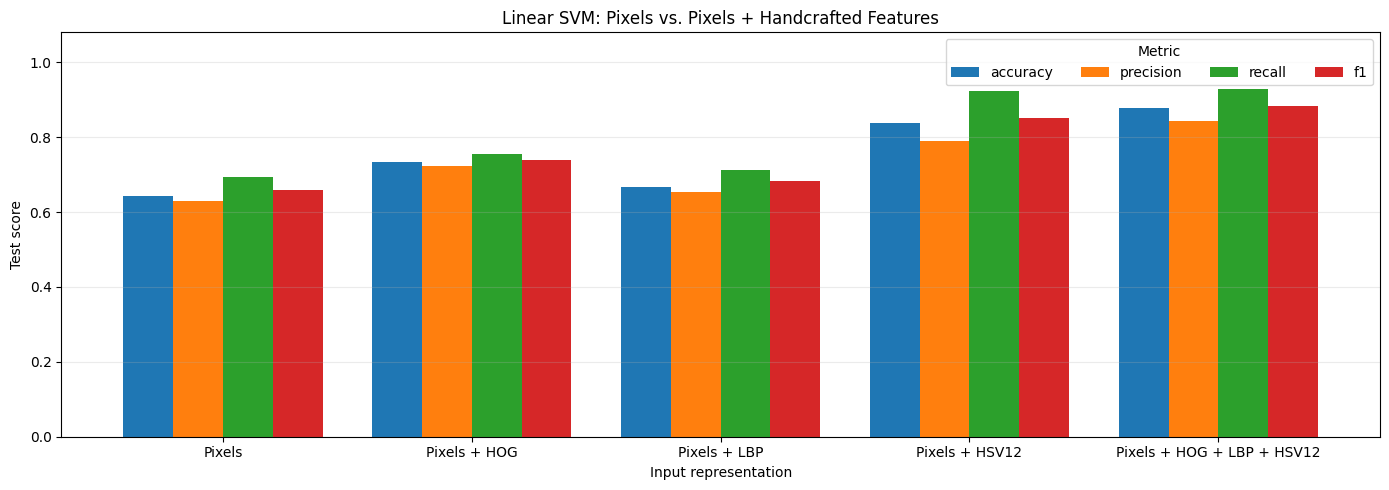

Saved test_metrics_comparison.png and test_metrics.csv.


In [12]:
# Use the same 0-1 score scale for all five inputs and metrics.
plot_data = test_metrics.set_index("input")[METRIC_COLUMNS]
axis = plot_data.plot.bar(figsize=(14, 5), ylim=(0, 1.08), rot=0, width=0.8)
axis.set_xlabel("Input representation")
axis.set_ylabel("Test score")
axis.set_title("Linear SVM: Pixels vs. Pixels + Handcrafted Features")
axis.legend(title="Metric", loc="upper right", ncol=4)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_metrics_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved test_metrics_comparison.png and test_metrics.csv.")


## 8. Confusion Matrices

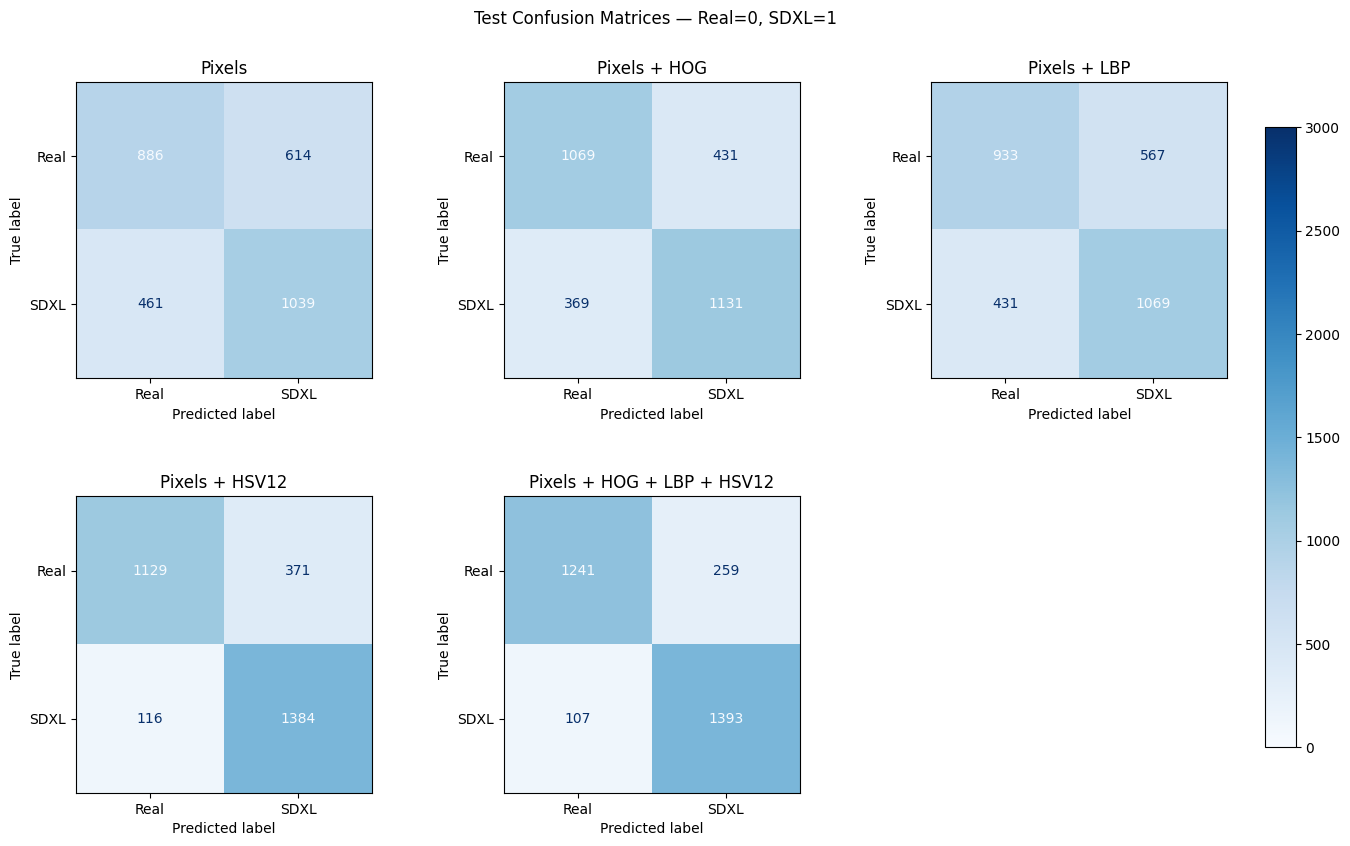

Saved test_confusion_matrices.png and five confusion-matrix CSV files.


In [13]:
experiment_names = ["pixels", "pixels_hog", "pixels_lbp", "pixels_hsv12", "pixels_all"]
input_names = ["Pixels", "Pixels + HOG", "Pixels + LBP", "Pixels + HSV12", "Pixels + HOG + LBP + HSV12"]
confusion_matrices = [cm_pixels, cm_hog, cm_lbp, cm_hsv12, cm_all]

figure, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for index in range(5):
    matrix = confusion_matrices[index]
    display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=CLASS_NAMES)
    display.plot(
        ax=axes[index], cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": len(y_test)},
    )
    axes[index].set_title(input_names[index])
    matrix_table = pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES)
    matrix_table.index.name = "true_label"
    matrix_table.to_csv(OUTPUT_DIR / f"{experiment_names[index]}_confusion_matrix.csv")

axes[5].axis("off")
figure.suptitle("Test Confusion Matrices — Real=0, SDXL=1")
figure.subplots_adjust(wspace=0.35, hspace=0.4, right=0.9, top=0.9)
figure.colorbar(display.im_, ax=axes[:5].tolist(), fraction=0.025, pad=0.03)
figure.savefig(OUTPUT_DIR / "test_confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved test_confusion_matrices.png and five confusion-matrix CSV files.")


## 9. Output

In [14]:
training_history = pd.concat(
    [svm_pixels.history, svm_hog.history, svm_lbp.history, svm_hsv12.history, svm_all.history], ignore_index=True
)
training_history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
split_counts = {"train": len(y_train), "val": len(y_val), "test": len(y_test)}
run_summary = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "config": RUN_CONFIG,
    "config_sha256": RUN_CONFIG_SHA256,
    "library_versions": LIBRARY_VERSIONS,
    "sources": source_info,
    "split_counts": split_counts,
    "test_metrics": test_metrics.to_dict(orient="records"),
}
summary_path = OUTPUT_DIR / "benchmark_summary.json"
summary_path.write_text(json.dumps(run_summary, indent=2), encoding="utf-8")

comparison = test_metrics[["input", "accuracy", "precision", "recall", "f1"]].copy()
for metric in METRIC_COLUMNS:
    baseline_score = result_pixels[metric]
    comparison[f"delta_{metric}"] = comparison[metric] - baseline_score
comparison.to_csv(OUTPUT_DIR / "comparison_vs_pixels.csv", index=False)
print(comparison.round(4).to_string(index=False))

output_files = []
for file_path in sorted(OUTPUT_DIR.rglob("*")):
    if file_path.is_file():
        output_files.append({
            "file": str(file_path.relative_to(OUTPUT_DIR)),
            "size_MiB": round(file_path.stat().st_size / 2**20, 3),
        })
print(pd.DataFrame(output_files).to_string(index=False))
print("Output directory:", OUTPUT_DIR)

                     input  accuracy  precision  recall     f1  delta_accuracy  delta_precision  delta_recall  delta_f1
                    Pixels    0.6417     0.6286  0.6927 0.6591          0.0000           0.0000        0.0000    0.0000
              Pixels + HOG    0.7333     0.7241  0.7540 0.7387          0.0917           0.0955        0.0613    0.0797
              Pixels + LBP    0.6673     0.6534  0.7127 0.6818          0.0257           0.0249        0.0200    0.0227
            Pixels + HSV12    0.8377     0.7886  0.9227 0.8504          0.1960           0.1600        0.2300    0.1913
Pixels + HOG + LBP + HSV12    0.8780     0.8432  0.9287 0.8839          0.2363           0.2147        0.2360    0.2248
                                         file  size_MiB
                       benchmark_summary.json     0.005
                     comparison_vs_pixels.csv     0.001
          models/pixels_all_linear_svm.joblib     4.544
       models/pixels_all_training_history.csv     0.002
